In [2]:
"""
Layer-wise probing of a (light-weight) BERT on 3 SentEval probing tasks:
sentence length, bigram shift, subject number.

Usage:
    pip install torch transformers scikit-learn pandas matplotlib requests tqdm
    python probing_bert_layers.py --model distilbert-base-uncased   # 6 layers (light)
    python probing_bert_layers.py --model bert-base-uncased         # 12 layers
"""
import argparse, os, urllib.request
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from tqdm import tqdm
from transformers import AutoTokenizer, AutoModel
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

BASE = "https://raw.githubusercontent.com/facebookresearch/SentEval/main/data/probing/"
TASKS = {"sentence_length": "sentence_length.txt",
         "bigram_shift": "bigram_shift.txt",
         "subj_number": "subj_number.txt"}

ap = argparse.ArgumentParser()
ap.add_argument("--model", default="distilbert-base-uncased")
ap.add_argument("--n_samples", type=int, default=50000)
ap.add_argument("--batch_size", type=int, default=128)
ap.add_argument("--max_len", type=int, default=64)
ap.add_argument("--seed", type=int, default=42)
ap.add_argument("--out", default="results")
args, _ = ap.parse_known_args()
os.makedirs(args.out, exist_ok=True)
os.makedirs("data", exist_ok=True)


def load_task(fname):
    path = os.path.join("data", fname)
    if not os.path.exists(path):
        urllib.request.urlretrieve(BASE + fname, path)
    rows = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            parts = line.rstrip("\n").split("\t")
            if len(parts) >= 3:           # format: split <tab> label <tab> sentence
                rows.append((parts[1], parts[2]))
    return pd.DataFrame(rows, columns=["label", "sentence"])


def balanced_sample(df, n_total, seed):
    """Equal number of samples per class (n_total // n_classes each)."""
    k = df.label.nunique()
    per_class = n_total // k
    parts = []
    for _, g in df.groupby("label"):
        parts.append(g.sample(n=min(per_class, len(g)), random_state=seed))
    return pd.concat(parts).sample(frac=1, random_state=seed).reset_index(drop=True)


device = "cuda" if torch.cuda.is_available() else "cpu"
tok = AutoTokenizer.from_pretrained(args.model)
model = AutoModel.from_pretrained(args.model, output_hidden_states=True).to(device).eval()
if device == "cuda":
    model.half()


@torch.no_grad()
def encode(sentences):
    """Returns array [N, n_layers+1, hidden]; mean-pooled over real tokens.
    Index 0 = embedding output, 1..L = encoder layers."""
    out = []
    for i in tqdm(range(0, len(sentences), args.batch_size), leave=False):
        b = tok(sentences[i:i + args.batch_size], padding=True, truncation=True,
                max_length=args.max_len, return_tensors="pt").to(device)
        hs = model(**b).hidden_states                    # tuple of [B, T, H]
        m = b["attention_mask"].unsqueeze(-1).float()
        pooled = [((h.float() * m).sum(1) / m.sum(1)).cpu().numpy() for h in hs]
        out.append(np.stack(pooled, axis=1))
    return np.concatenate(out)


results = {}
for task, fname in TASKS.items():
    print(f"\n=== {task} ===")
    df = balanced_sample(load_task(fname), args.n_samples, args.seed)
    print(f"{len(df)} samples; class counts:\n{df.label.value_counts().to_dict()}")

    tr, te = train_test_split(df, test_size=0.1, stratify=df.label, random_state=args.seed)
    Xtr, Xte = encode(tr.sentence.tolist()), encode(te.sentence.tolist())
    ytr, yte = tr.label.values, te.label.values

    accs = []
    for layer in range(Xtr.shape[1]):
        sc = StandardScaler().fit(Xtr[:, layer])
        clf = LogisticRegression(max_iter=1000, n_jobs=-1)
        clf.fit(sc.transform(Xtr[:, layer]), ytr)
        acc = accuracy_score(yte, clf.predict(sc.transform(Xte[:, layer])))
        accs.append(acc)
        print(f"  layer {layer:2d}: test acc = {acc:.4f}")
    results[task] = accs

res = pd.DataFrame(results)
res.index.name = "layer (0=embeddings)"
res.to_csv(f"{args.out}/layerwise_accuracy.csv")
print("\n", res.round(4))

plt.figure(figsize=(7, 4.5))
for task in results:
    plt.plot(res.index, res[task], marker="o", label=task)
plt.xlabel("Layer (0 = embeddings)"); plt.ylabel("Test accuracy")
plt.title(f"Layer-wise probing: {args.model}")
plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
plt.savefig(f"{args.out}/layerwise_accuracy.png", dpi=150)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



=== sentence_length ===
49998 samples; class counts:
{'4': 8333, '1': 8333, '0': 8333, '5': 8333, '2': 8333, '3': 8333}


KeyboardInterrupt: 

device: cpu | batch size: 64


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



=== sentence_length ===
49998 samples; class counts: {'4': 8333, '1': 8333, '0': 8333, '5': 8333, '2': 8333, '3': 8333}
   encoded 64/44998
   encoded 1344/44998
   encoded 2624/44998
   encoded 3904/44998
   encoded 5184/44998
   encoded 6464/44998
   encoded 7744/44998
   encoded 9024/44998
   encoded 10304/44998
   encoded 11584/44998
   encoded 12864/44998
   encoded 14144/44998
   encoded 15424/44998
   encoded 16704/44998
   encoded 17984/44998
   encoded 19264/44998
   encoded 20544/44998
   encoded 21824/44998
   encoded 23104/44998
   encoded 24384/44998
   encoded 25664/44998
   encoded 26944/44998
   encoded 28224/44998
   encoded 29504/44998
   encoded 30784/44998
   encoded 32064/44998
   encoded 33344/44998
   encoded 34624/44998
   encoded 35904/44998
   encoded 37184/44998
   encoded 38464/44998
   encoded 39744/44998
   encoded 41024/44998
   encoded 42304/44998
   encoded 43584/44998
   encoded 44864/44998
   encoded 64/5000
   encoded 1344/5000
   encoded 2624/5000


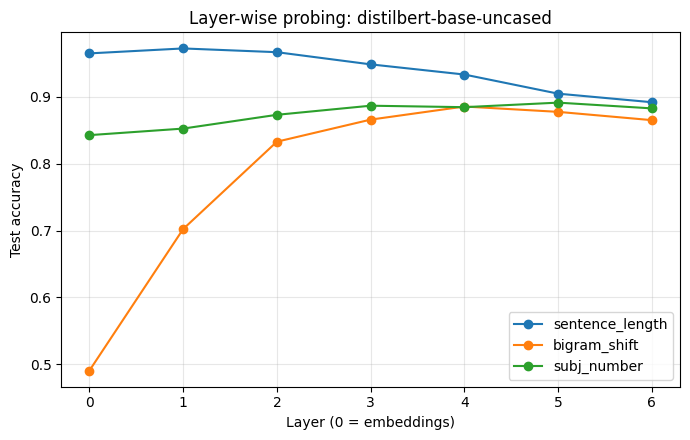

In [3]:
"""
Fast layer-wise probing of BERT on SentEval probing tasks
(sentence_length, bigram_shift, subj_number). Works as a script or in Colab.
Use a GPU runtime (Runtime -> Change runtime type -> T4 GPU).
"""
import argparse, os, urllib.request, time
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel
from sklearn.model_selection import train_test_split

BASE = "https://raw.githubusercontent.com/facebookresearch/SentEval/main/data/probing/"
TASKS = {"sentence_length": "sentence_length.txt",
         "bigram_shift": "bigram_shift.txt",
         "subj_number": "subj_number.txt"}

ap = argparse.ArgumentParser()
ap.add_argument("--model", default="distilbert-base-uncased")  # or bert-base-uncased
ap.add_argument("--n_samples", type=int, default=50000)
ap.add_argument("--batch_size", type=int, default=0)           # 0 = auto
ap.add_argument("--max_len", type=int, default=64)
ap.add_argument("--seed", type=int, default=42)
ap.add_argument("--out", default="results")
args, _ = ap.parse_known_args()
os.makedirs(args.out, exist_ok=True); os.makedirs("data", exist_ok=True); os.makedirs("feats", exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
bs = args.batch_size or (256 if device == "cuda" else 64)
if device == "cpu":
    print("WARNING: running on CPU -> slow. Switch Colab to a GPU runtime.")
    torch.set_num_threads(os.cpu_count())
print("device:", device, "| batch size:", bs)

tok = AutoTokenizer.from_pretrained(args.model)
model = AutoModel.from_pretrained(args.model, output_hidden_states=True).to(device).eval()
if device == "cuda":
    model.half()


def load_task(fname):
    path = os.path.join("data", fname)
    if not os.path.exists(path):
        urllib.request.urlretrieve(BASE + fname, path)
    rows = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            p = line.rstrip("\n").split("\t")
            if len(p) >= 3:
                rows.append((p[1], p[2]))
    return pd.DataFrame(rows, columns=["label", "sentence"])


def balanced_sample(df, n_total, seed):
    per_class = n_total // df.label.nunique()
    parts = [g.sample(n=min(per_class, len(g)), random_state=seed) for _, g in df.groupby("label")]
    return pd.concat(parts).sample(frac=1, random_state=seed).reset_index(drop=True)


@torch.inference_mode()
def encode(sentences):
    """[N, n_layers+1, H] mean-pooled features. Sorted by length to cut padding."""
    enc = tok(sentences, truncation=True, max_length=args.max_len)["input_ids"]
    order = np.argsort([len(x) for x in enc])
    out = None
    for i in range(0, len(order), bs):
        idx = order[i:i + bs]
        b = tok.pad({"input_ids": [enc[j] for j in idx]}, return_tensors="pt").to(device)
        hs = torch.stack(model(**b).hidden_states, dim=1).float()      # B, L+1, T, H
        m = b["attention_mask"][:, None, :, None].float()
        pooled = ((hs * m).sum(2) / m.sum(2)).cpu().numpy().astype(np.float32)
        if out is None:
            out = np.zeros((len(order),) + pooled.shape[1:], dtype=np.float32)
        out[idx] = pooled
        if (i // bs) % 20 == 0:
            print(f"   encoded {min(i + bs, len(order))}/{len(order)}", flush=True)
    return out


def logreg_acc(Xtr, ytr, Xte, yte, n_cls, l2=1e-4, iters=150):
    """Multinomial logistic regression (L-BFGS, L2) on standardized features."""
    Xtr = torch.tensor(Xtr, device=device); Xte = torch.tensor(Xte, device=device)
    mu, sd = Xtr.mean(0, keepdim=True), Xtr.std(0, keepdim=True) + 1e-6
    Xtr, Xte = (Xtr - mu) / sd, (Xte - mu) / sd
    ytr_t = torch.tensor(ytr, device=device)
    lin = torch.nn.Linear(Xtr.shape[1], n_cls).to(device)
    opt = torch.optim.LBFGS(lin.parameters(), lr=1, max_iter=iters,
                            history_size=20, line_search_fn="strong_wolfe")
    def closure():
        opt.zero_grad()
        loss = torch.nn.functional.cross_entropy(lin(Xtr), ytr_t) + l2 * (lin.weight ** 2).sum()
        loss.backward(); return loss
    opt.step(closure)
    with torch.no_grad():
        return (lin(Xte).argmax(1).cpu().numpy() == yte).mean()


tag = args.model.replace("/", "_")
results = {}
for task, fname in TASKS.items():
    print(f"\n=== {task} ===")
    t0 = time.time()
    df = balanced_sample(load_task(fname), args.n_samples, args.seed)
    classes = sorted(df.label.unique()); cmap = {c: i for i, c in enumerate(classes)}
    print(f"{len(df)} samples; class counts: {df.label.value_counts().to_dict()}")
    tr, te = train_test_split(df, test_size=0.1, stratify=df.label, random_state=args.seed)
    ytr = tr.label.map(cmap).values; yte = te.label.map(cmap).values

    fpath = f"feats/{tag}_{task}.npz"
    if os.path.exists(fpath):
        d = np.load(fpath); Xtr, Xte = d["Xtr"], d["Xte"]
    else:
        Xtr, Xte = encode(tr.sentence.tolist()), encode(te.sentence.tolist())
        np.savez(fpath, Xtr=Xtr, Xte=Xte)
    print(f"features ready in {time.time()-t0:.0f}s")

    accs = []
    for layer in range(Xtr.shape[1]):
        acc = float(logreg_acc(Xtr[:, layer], ytr, Xte[:, layer], yte, len(classes)))
        accs.append(acc); print(f"  layer {layer:2d}: test acc = {acc:.4f}")
    results[task] = accs

res = pd.DataFrame(results); res.index.name = "layer (0=embeddings)"
res.to_csv(f"{args.out}/layerwise_accuracy_{tag}.csv")
print("\n", res.round(4))

plt.figure(figsize=(7, 4.5))
for t in results: plt.plot(res.index, res[t], marker="o", label=t)
plt.xlabel("Layer (0 = embeddings)"); plt.ylabel("Test accuracy")
plt.title(f"Layer-wise probing: {args.model}"); plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
plt.savefig(f"{args.out}/layerwise_accuracy_{tag}.png", dpi=150)
if "ipykernel" in __import__("sys").modules: plt.show()